In [21]:
import os

import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Image
import re
from wordfreq import zipf_frequency


sys.path.append("../src")
from surprisal import tok, lm, dev, full_surprisal, lossy_surprisal
from ns_data import load_stories
import surprisal

LAMS = [1, 2, 4, 8]

2(a) Full and lossy surprisals

In [22]:
SC_DIR = Path("../data/structuralcost")
sc = pd.concat([pd.read_csv(SC_DIR / "StructuralCost_critical.csv"),
                pd.read_csv(SC_DIR / "StructuralCost_control.csv")], ignore_index=True)
sc["split"] = sc["tag"].map({"exp-1": "critical", "exp-2": "control"})
sc["item"] = sc["split"] + "_" + sc["setID"].astype(str)
print(len(sc), "rows,", sc["sentID_in_dataset"].nunique(), "sentences")

595734 rows, 450 sentences


In [23]:
# one row per word of each sentence (every participant repeats them)
words = (sc[["sentID_in_dataset", "wordID", "word"]]
         .drop_duplicates()
         .sort_values(["sentID_in_dataset", "wordID"]))
assert not words.duplicated(["sentID_in_dataset", "wordID"]).any(), "same position, different words"

sentences = {s: g["word"].tolist() for s, g in words.groupby("sentID_in_dataset")}

# one row per sentence, with what we need about it
sents = (sc.drop_duplicates("sentID_in_dataset")
         [["sentID_in_dataset", "item", "split", "sentence_structure", "dep_length", "root_i"]]
         .reset_index(drop=True))
sents["verb"] = [sentences[s][i] for s, i in zip(sents["sentID_in_dataset"], sents["root_i"])]
sents["context"] = [sentences[s][:i] for s, i in zip(sents["sentID_in_dataset"], sents["root_i"])]

print(len(sents), "sentences")
for _, r in sents.sample(5, random_state=0).iterrows():
    print(f"{r['sentence_structure']:16} {' '.join(r['context'])} [{r['verb']}]")

450 sentences
baseline-1       The raindrops [cover]
standard-subject The sailor that called the navigator [unfolds]
nested-object    The detective that the witness that the abandoned warehouse housed questioned [catalogs]
nested-subject   The columnist that consulted the editor that was in the office [graces]
standard-object  The mother that the neighbor called [comforts]


In [24]:
RUN_SURP = False

if RUN_SURP:
    t0 = time.time()
    rows = []
    for _, r in sents.iterrows():
        row = {"sentID_in_dataset": r["sentID_in_dataset"],
            "surp_full": full_surprisal(r["context"], r["verb"])}
        for lam in LAMS:
            # fixed seed for each sentence and lambda, as for Natural Stories
            surprisal.rng = np.random.default_rng([int(r["sentID_in_dataset"]), lam])
            row[f"surp_lam{lam}"] = lossy_surprisal(r["context"], r["verb"], lam=lam)
        rows.append(row)

    sc_surp = sents.drop(columns="context").merge(pd.DataFrame(rows), on="sentID_in_dataset")
    sc_surp.to_csv("../results/sc_surp.csv", index=False)
    print(f"{len(sc_surp)} verbs in {time.time() - t0:.0f} s")

In [25]:
sc_surp = pd.read_csv("../results/sc_surp.csv")

In [26]:
cols = ["surp_full"] + [f"surp_lam{lam}" for lam in LAMS]
print(sc_surp[cols].describe().round(2))
print(sc_surp.groupby(["split", "sentence_structure"])[cols].mean().round(2))

       surp_full  surp_lam1  surp_lam2  surp_lam4  surp_lam8
count     450.00     450.00     450.00     450.00     450.00
mean       17.80      20.87      18.94      18.25      18.20
std         4.25       3.69       3.63       3.67       3.78
min         8.58      13.10      11.44      10.95       9.89
25%        14.98      18.53      16.64      15.69      15.64
50%        17.31      20.32      18.39      17.64      17.73
75%        20.22      22.64      20.71      20.04      20.25
max        38.13      37.66      35.84      35.51      35.93
                             surp_full  surp_lam1  surp_lam2  surp_lam4  \
split    sentence_structure                                               
control  baseline-2              14.91      19.35      17.11      15.97   
         pp-long                 15.70      19.43      17.61      17.03   
         pp-short                14.74      19.71      17.44      16.33   
critical baseline-1              16.68      20.84      19.13      17.88   
 

In [27]:
print(sc_surp.groupby(["split", "sentence_structure"])["dep_length"].unique())

split     sentence_structure
control   baseline-2            [0]
          pp-long               [9]
          pp-short              [4]
critical  baseline-1            [0]
          control               [4]
          nested-object         [9]
          nested-subject        [9]
          standard-object       [4]
          standard-subject      [4]
Name: dep_length, dtype: object


2(b) Predicted surprisal vs distance

In [28]:
ctrl = sc_surp[sc_surp["split"] == "control"]
means = ctrl.groupby("dep_length")[cols].mean()
sems = ctrl.groupby("dep_length")[cols].sem()      # standard error: how precise each mean is

print(means.round(2))
print("\nchange from distance 0 to 9:")
print((means.loc[9] - means.loc[0]).round(2))

            surp_full  surp_lam1  surp_lam2  surp_lam4  surp_lam8
dep_length                                                       
0               14.91      19.35      17.11      15.97      15.47
4               14.74      19.71      17.44      16.33      15.87
9               15.70      19.43      17.61      17.03      16.95

change from distance 0 to 9:
surp_full    0.79
surp_lam1    0.08
surp_lam2    0.50
surp_lam4    1.07
surp_lam8    1.48
dtype: float64


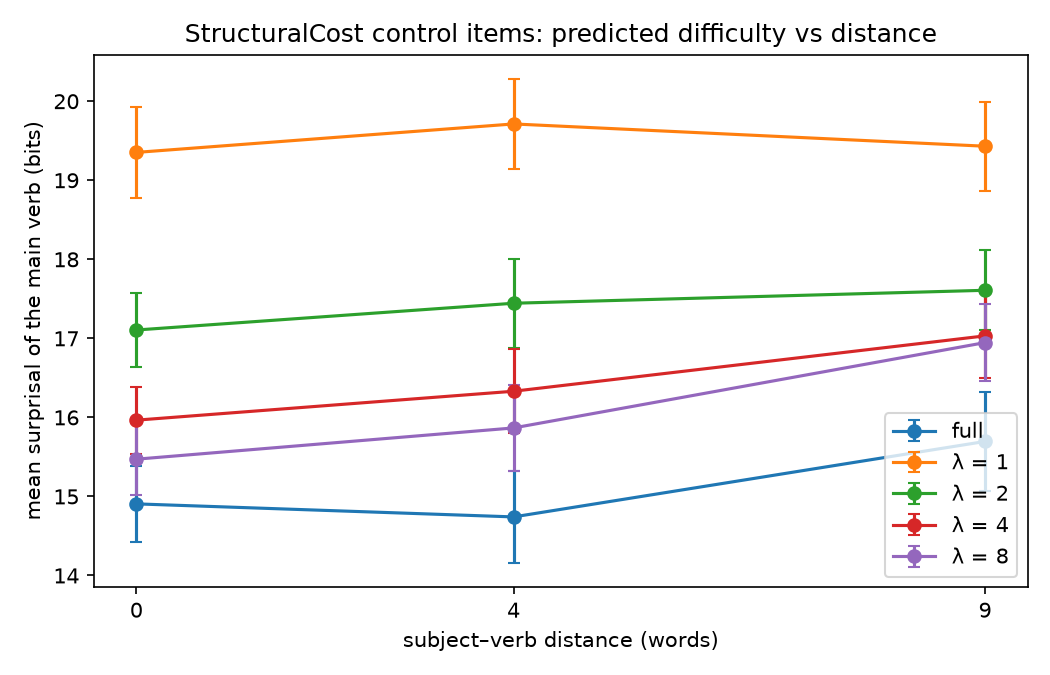

In [29]:
labels = {"surp_full": "full"} | {f"surp_lam{lam}": f"λ = {lam}" for lam in LAMS}

fig, ax = plt.subplots(figsize=(7, 4.5))
for c in cols:
    ax.errorbar(means.index, means[c], yerr=sems[c], marker="o", capsize=3, label=labels[c])
ax.set_xticks([0, 4, 9])
ax.set_xlabel("subject–verb distance (words)")
ax.set_ylabel("mean surprisal of the main verb (bits)")
ax.set_title("StructuralCost control items: predicted difficulty vs distance")
ax.legend()
plt.tight_layout()

plt.savefig("../figures/sc_control_distance.pdf")
plt.savefig("../figures/sc_control_distance.png", dpi=150)
plt.close(fig)
Image("../figures/sc_control_distance.png")

In [30]:
ctrl = sc_surp[sc_surp["split"] == "control"]
for item in ctrl["item"].unique()[:3]:
    print(ctrl[ctrl["item"] == item][["dep_length", "verb", "surp_full"]].to_string(index=False))

 dep_length   verb  surp_full
          4 sweeps  15.233462
          0 sweeps  13.780268
          9 sweeps  16.450014
 dep_length   verb  surp_full
          9 shouts  11.945133
          4 shouts  10.079101
          0 shouts  14.354719
 dep_length  verb  surp_full
          0 sweep  16.895823
          9 sweep  17.915990
          4 sweep  18.301098


2(c)

In [31]:
crit = sc_surp[sc_surp["split"] == "critical"]
wide = crit.pivot_table(index="item", columns="sentence_structure", values=cols)   # one row per set

rows = []
for kind in ["subject", "object"]:
    for c in cols:
        diff = wide[(c, f"nested-{kind}")] - wide[(c, f"standard-{kind}")]   # < 0: nested is easier
        rows.append({"comparison": f"2x{kind[0].upper()}RC - {kind[0].upper()}RC",
                     "predictor": labels[c],
                     "mean diff": diff.mean(),
                     "sem": diff.sem(),
                     "% sets nested easier": (diff < 0).mean() * 100})
res = pd.DataFrame(rows)
print(res.round(2).to_string(index=False))

 comparison predictor  mean diff  sem  % sets nested easier
2xSRC - SRC      full      -0.54 0.27                 61.67
2xSRC - SRC     λ = 1       0.42 0.17                 30.00
2xSRC - SRC     λ = 2       0.53 0.22                 38.33
2xSRC - SRC     λ = 4       0.43 0.23                 40.00
2xSRC - SRC     λ = 8       0.02 0.28                 53.33
2xORC - ORC      full       0.51 0.19                 38.33
2xORC - ORC     λ = 1       0.02 0.12                 46.67
2xORC - ORC     λ = 2       0.07 0.11                 41.67
2xORC - ORC     λ = 4      -0.11 0.16                 58.33
2xORC - ORC     λ = 8      -0.17 0.20                 51.67


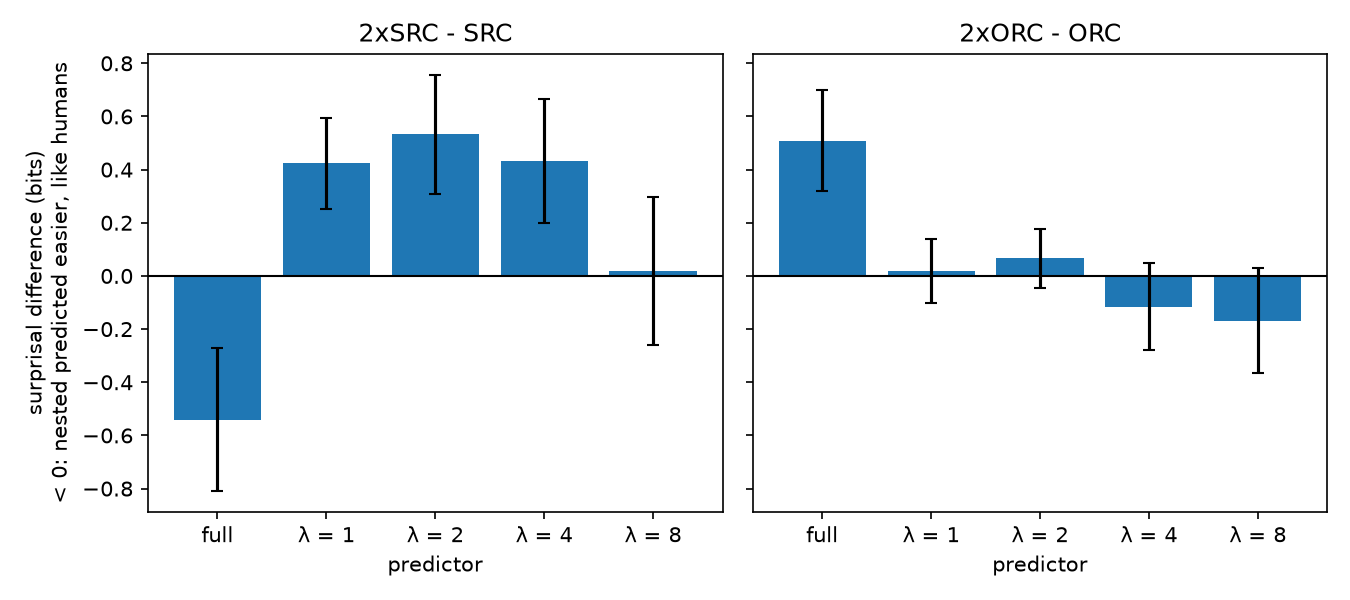

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, comp in zip(axes, res["comparison"].unique()):
    r = res[res["comparison"] == comp]
    ax.bar(r["predictor"], r["mean diff"], yerr=r["sem"], capsize=3)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(comp)
    ax.set_xlabel("predictor")
axes[0].set_ylabel("surprisal difference (bits)\n< 0: nested predicted easier, like humans")
plt.tight_layout()

plt.savefig("../figures/sc_nested_vs_standard.pdf")
plt.savefig("../figures/sc_nested_vs_standard.png", dpi=150)
plt.close(fig)
Image("../figures/sc_nested_vs_standard.png")

2(d) Building verbs (and previous word) table

In [33]:
RUN_SURP_PREV = False

if RUN_SURP_PREV:
    rows = []
    for _, r in sc_surp.iterrows():
        s, i = int(r["sentID_in_dataset"]), int(r["root_i"])
        prev_word, prev_context = sentences[s][i - 1], sentences[s][:i - 1]   # word before the verb, and its own context
        row = {"sentID_in_dataset": s, "prev_word": prev_word,
            "surp_full_prev": full_surprisal(prev_context, prev_word)}
        for lam in LAMS:
            surprisal.rng = np.random.default_rng([s, lam, 1])   # different seed from the verb's
            row[f"surp_lam{lam}_prev"] = lossy_surprisal(prev_context, prev_word, lam=lam)
        rows.append(row)

    sc_surp_prev = sc_surp.merge(pd.DataFrame(rows), on="sentID_in_dataset")
    sc_surp_prev.to_csv("../results/sc_surp_with_prev.csv", index=False)

In [34]:
def word_length(w):
    return len(re.sub(r"[^\w]", "", w))       # letters only

sc_surp_prev["freq"] = [zipf_frequency(w, "en") for w in sc_surp_prev["verb"]]
sc_surp_prev["length"] = [word_length(w) for w in sc_surp_prev["verb"]]
sc_surp_prev["freq_prev"] = [zipf_frequency(w, "en") for w in sc_surp_prev["prev_word"]]
sc_surp_prev["length_prev"] = [word_length(w) for w in sc_surp_prev["prev_word"]]

In [35]:
# data names -> the project's names
CONDITION = {"baseline-1": "Baseline", "control": "PP", "standard-subject": "SRC",
             "standard-object": "ORC", "nested-subject": "2xSRC", "nested-object": "2xORC",
             "baseline-2": "PP0", "pp-short": "PP4", "pp-long": "PP9"}

rt = sc[sc["wordID"] == sc["root_i"]][["participantID", "sentID_in_dataset", "reactionTime"]]   # RT on the main verb
rt = rt.rename(columns={"participantID": "subject"})
rt = rt[rt["reactionTime"].between(100, 3000)]
rt["logRT"] = np.log(rt["reactionTime"])

d = rt.merge(sc_surp_prev, on="sentID_in_dataset")
d["condition"] = d["sentence_structure"].map(CONDITION)
d["distance"] = d["dep_length"]

predictors = (["freq", "length", "freq_prev", "length_prev", "distance"]
              + cols + [f"{c}_prev" for c in cols])
for c in predictors:
    d[c] = (d[c] - d[c].mean()) / d[c].std()

sc_verbs = d[["subject", "item", "condition", "split", "sentID_in_dataset", "verb", "logRT"] + predictors]
sc_verbs.to_csv("../results/sc_verbs.csv", index=False)

print(sc_verbs.shape, sc_verbs["subject"].nunique(), "participants,",
      sc_verbs["sentID_in_dataset"].nunique(), "sentences")
assert sc_verbs[predictors + ["condition"]].notna().all().all(), "empty values"
print(sc_verbs.groupby("condition").size())

(42517, 22) 475 participants, 450 sentences
condition
2xORC       4706
2xSRC       4732
Baseline    4731
ORC         4689
PP          4735
PP0         4729
PP4         4736
PP9         4738
SRC         4721
dtype: int64
